# Stage 3 — An inverse PINN by hand

**Vamsi Gudipati**

A minimal inverse PINN written by hand: a 1–16–1 network and an unknown λ are trained together so that y'' + λy = 0 holds at 100 collocation points and the network passes through four observations of sin(2x); the true λ is 4. It is the same idea as the conductivity problem of Stage 2, without the library. I added a training animation and repeated the training with three seeds, because the notebook itself sets no seed.

Portfolio page: https://vamsigudipati.github.io/physics-informed-pinn-deeponet.html


In [1]:
# Where this notebook writes its outputs (paths relative to notebooks/)
from pathlib import Path
STAGE = "03_inverse_pinn_by_hand"
RESULTS_DIR = Path("../results") / STAGE
EXERCISES_DIR = RESULTS_DIR / "exercises"
MODELS_DIR = Path("../models") / STAGE
ANIM_DIR = Path("../animations")
ANIM_PREFIX = "03_"
for _d in (RESULTS_DIR, EXERCISES_DIR, MODELS_DIR, ANIM_DIR):
    _d.mkdir(parents=True, exist_ok=True)

In [2]:
# Training-animation hook: records the unknown λ, the loss and the prediction during the first training loop,
# and a checkpoint every 2,000 iterations. It only evaluates the network under no_grad, so the training is unchanged.
import numpy as np, pickle, torch
from pathlib import Path
ANIM, MODELS = ANIM_DIR, MODELS_DIR
ex_snaps, EX_HOOK_ACTIVE = [], [True]
def ex_hook(i, net, lam, loss, x):
    if not EX_HOOK_ACTIVE[0]: return
    if i % 100 == 0 or i == 9999:
        with torch.no_grad(): yp = net(x).detach().numpy().ravel().copy()
        ex_snaps.append(dict(it=i, lam=float(lam.item()), loss=float(loss.item()), y=yp))
    if i % 2000 == 0 or i == 9999: torch.save({"net": net.state_dict(), "lam": lam.detach().clone()}, MODELS / f"inverse_pinn_it{i:05d}.pth")
    if i == 9999: EX_HOOK_ACTIVE[0] = False

True λ      = 4
Estimated λ = 3.983837366104126


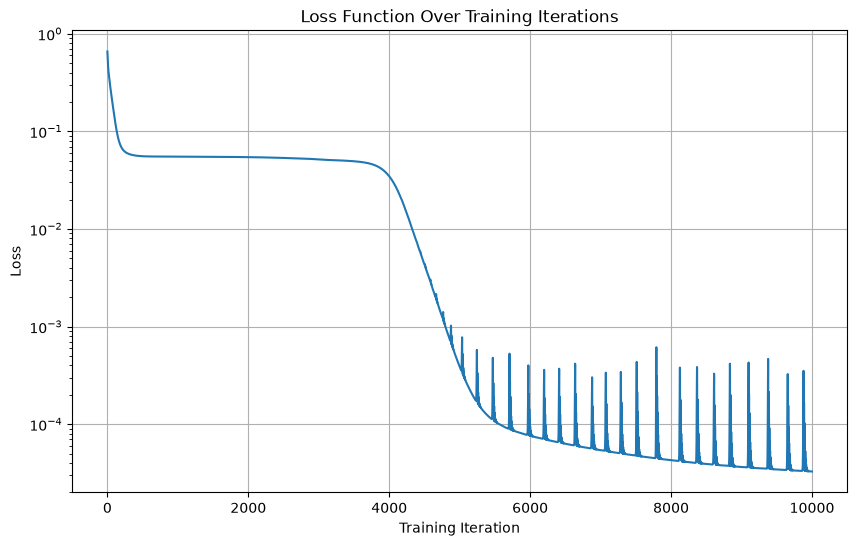

In [3]:
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

# Collocation points
x = torch.linspace(0, 3.14, 100).reshape(-1, 1)
x.requires_grad_(True)

# Sparse observations
x_data = torch.tensor([[0.5],
                       [1.0],
                       [1.5],
                       [2.0]])

y_data = torch.sin(2 * x_data)   # synthetic measurements

# MLP
net = nn.Sequential(
    nn.Linear(1, 16),
    nn.Tanh(),
    nn.Linear(16, 1)
)

# Unknown parameter λ
lam = nn.Parameter(torch.tensor([1.0]))

opt = torch.optim.Adam(
    list(net.parameters()) + [lam],
    lr=2e-3
)

# List to store loss values for plotting
loss_history = []

# Training
for i in range(10000):

    # Prediction
    y = net(x)

    # First derivative
    dy = torch.autograd.grad(
        y, x,
        grad_outputs=torch.ones_like(y),
        create_graph=True)[0]

    # Second derivative
    d2y = torch.autograd.grad(
        dy, x,
        grad_outputs=torch.ones_like(dy),
        create_graph=True)[0]

    # Physics
    ode_loss = ((d2y + lam * y) ** 2).mean()

    # Data mismatch
    y_pred_data = net(x_data)
    data_loss = ((y_pred_data - y_data) ** 2).mean()

    loss = ode_loss + data_loss
    opt.zero_grad()
    loss.backward()
    opt.step()

    loss_history.append(loss.item())
    ex_hook(i, net, lam, loss, x)  # hook: animation snapshot and checkpoint

print("True λ      = 4")
print("Estimated λ =", lam.item())

# Plot the loss history
plt.figure(figsize=(10, 6))
plt.plot(loss_history)
plt.xlabel("Training Iteration")
plt.ylabel("Loss")
plt.title("Loss Function Over Training Iterations")
plt.grid(True)
plt.yscale('log') # Use a log scale for better visualization of decreasing loss
plt.show()

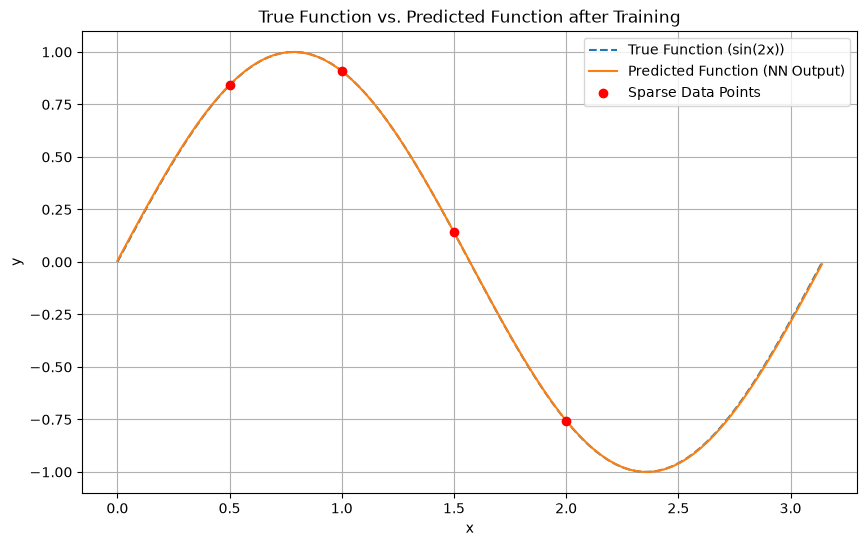

In [4]:
import numpy as np

# Get the predicted values from the trained network
# Detach from the computation graph and convert to numpy for plotting
predicted_y = net(x).detach().numpy()

# Get the true values (for visualization)
true_y = torch.sin(2 * x).detach().numpy()

# Convert x to numpy for plotting
x_np = x.detach().numpy()

plt.figure(figsize=(10, 6))
plt.plot(x_np, true_y, label='True Function (sin(2x))', linestyle='--')
plt.plot(x_np, predicted_y, label='Predicted Function (NN Output)')
plt.scatter(x_data.numpy(), y_data.numpy(), color='red', zorder=5, label='Sparse Data Points')
plt.xlabel('x')
plt.ylabel('y')
plt.title('True Function vs. Predicted Function after Training')
plt.legend()
plt.grid(True)
plt.show()

True λ      = 4
Estimated λ = 3.990103244781494


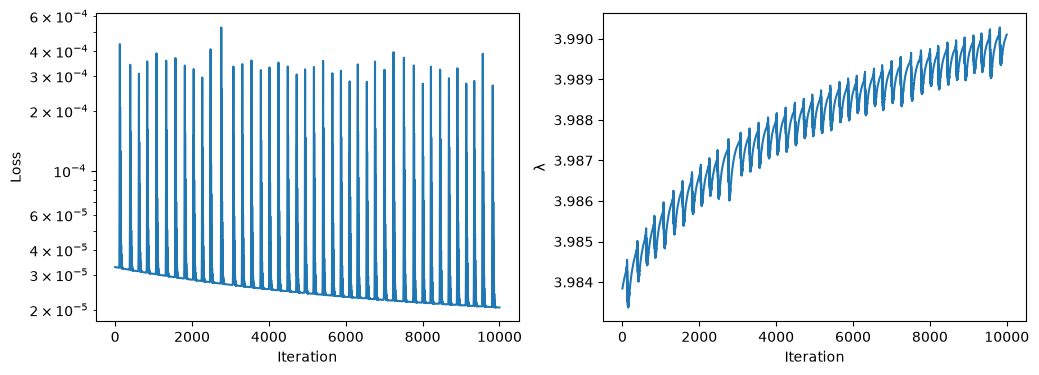

In [5]:
# Lists to store values for plotting
loss_history = []
lambda_history = []

# Training
for i in range(10000):
    # Prediction
    y = net(x)

    # First derivative
    dy = torch.autograd.grad(
        y, x,
        grad_outputs=torch.ones_like(y),
        create_graph=True)[0]

    # Second derivative
    d2y = torch.autograd.grad(
        dy, x,
        grad_outputs=torch.ones_like(dy),
        create_graph=True)[0]

    # Physics
    ode_loss = ((d2y + lam * y) ** 2).mean()

    # Data mismatch
    y_pred_data = net(x_data)
    data_loss = ((y_pred_data - y_data) ** 2).mean()

    loss = ode_loss + data_loss

    opt.zero_grad()
    loss.backward()
    opt.step()

    # Track metrics
    loss_history.append(loss.item())
    lambda_history.append(lam.item())

print("True λ      = 4")
print("Estimated λ =", lam.item())

# Plot the loss and lambda history
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

ax[0].plot(loss_history)
ax[0].set_yscale("log")
ax[0].set_xlabel("Iteration")
ax[0].set_ylabel("Loss")

ax[1].plot(lambda_history)
ax[1].set_xlabel("Iteration")
ax[1].set_ylabel("λ")

plt.show()

# Training animation and three seeds
**Animation.** The hook at the top recorded the first training loop every 100 iterations: the prediction on the 100 collocation points, the unknown λ and the loss. Video: `../animations/03_training_dashboard.mp4`; last frame: `../animations/03_final_frame.png`.

**Three seeds.** The notebook sets no seed, so its two λ estimates come from one unseeded run. I repeat the first loop (10,000 Adam iterations from λ = 1, a fresh network) with `torch.manual_seed` 0, 1 and 2 and report λ after 10,000 iterations, its error against the true value 4, the final loss and the root-mean-square error of the prediction against sin(2x) on the collocation points. Table and figure: `../results/03_inverse_pinn_by_hand/exercises/`.

In [6]:
from matplotlib.animation import FuncAnimation, FFMpegWriter
import imageio_ffmpeg, matplotlib.pyplot as plt
plt.rcParams["animation.ffmpeg_path"] = imageio_ffmpeg.get_ffmpeg_exe()
snaps = ex_snaps; pickle.dump(snaps, open(ANIM / f"{ANIM_PREFIX}snapshots.pkl", "wb"))
x_np_ = x.detach().numpy().ravel(); y_true_ = np.sin(2 * x_np_)
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
def anim_draw(k):
    s_ = snaps[k]
    for a in axes: a.clear()
    axes[0].plot(x_np_, y_true_, "--", label="sin(2x) (true)"); axes[0].plot(x_np_, s_["y"], label="network"); axes[0].scatter(x_data.numpy(), y_data.numpy(), color="red", zorder=5, label="4 observations")
    axes[0].set_ylim(-1.6, 1.6); axes[0].set_xlabel("x"); axes[0].set_title(f"prediction, iteration {s_['it']}"); axes[0].legend(fontsize=8)
    axes[1].plot([t["it"] for t in snaps[:k + 1]], [t["lam"] for t in snaps[:k + 1]], color="tab:green"); axes[1].axhline(4.0, color="k", ls="--", label="true λ = 4")
    axes[1].set_xlim(0, 10000); axes[1].set_ylim(0.5, 4.5); axes[1].set_xlabel("iteration"); axes[1].set_title(f"λ = {s_['lam']:.3f}"); axes[1].legend(fontsize=8)
    axes[2].semilogy([t["it"] for t in snaps[:k + 1]], [t["loss"] for t in snaps[:k + 1]], color="tab:blue"); axes[2].set_xlim(0, 10000); axes[2].set_ylim(1e-5, 10); axes[2].set_xlabel("iteration"); axes[2].set_title("loss (physics + data)")
    fig.suptitle("Stage 3 — inverse PINN recovering λ in y'' + λ y = 0 from four observations: training run"); fig.tight_layout()
anim_draw(len(snaps) - 1); fig.savefig(ANIM / f"{ANIM_PREFIX}final_frame.png", dpi=100)
FuncAnimation(fig, anim_draw, frames=len(snaps)).save(ANIM / f"{ANIM_PREFIX}training_dashboard.mp4", writer=FFMpegWriter(fps=10, bitrate=1600), dpi=90)
plt.close(fig); print(f"Animation: {len(snaps)} frames written; λ at the last snapshot {snaps[-1]['lam']:.4f}")

Animation: 101 frames written; λ at the last snapshot 3.9838


seed 0: λ = 3.9090 (2.28 %), loss 3.00e-04, 2.8 s


seed 1: λ = 3.8552 (3.62 %), loss 4.59e-04, 2.8 s


seed 2: λ = 3.9010 (2.47 %), loss 7.15e-04, 2.8 s
   seed      lam  rel_err_pct  final_loss  rmse_vs_sin2x  train_s
0     0  3.90897      2.27581     0.00030        0.01615      2.8
1     1  3.85519      3.62023     0.00046        0.02566      2.8
2     2  3.90103      2.47422     0.00072        0.01703      2.8
          lam  rel_err_pct  final_loss  rmse_vs_sin2x  train_s
mean  3.88840      2.79008     0.00049        0.01961      2.8
std   0.02903      0.72574     0.00021        0.00526      0.0


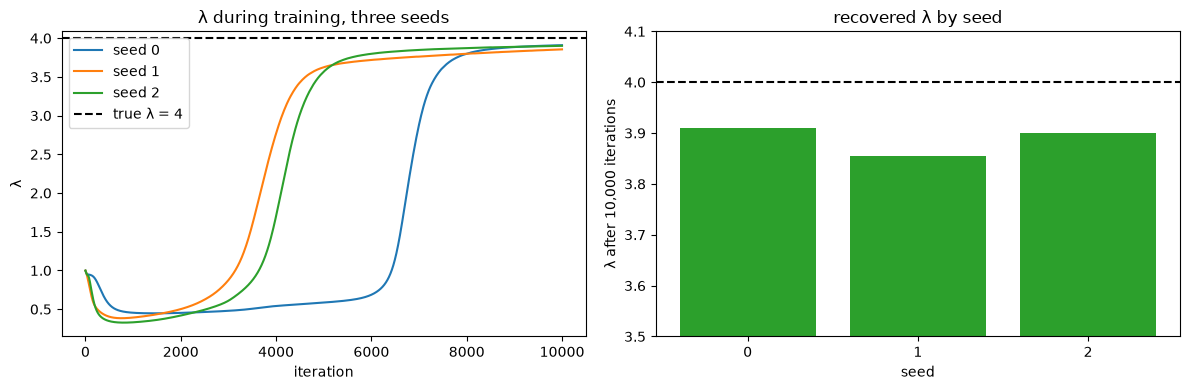

Result (three seeds): λ after 10,000 iterations = 3.8884 ± 0.0290 (true 4; relative error 2.79 ± 0.73 %)


In [7]:
import pandas as pd, time
ex_dir = EXERCISES_DIR; ex_dir.mkdir(exist_ok=True)
def train_seeded(seed, iters=10000):
    torch.manual_seed(seed)
    net_s = nn.Sequential(nn.Linear(1, 16), nn.Tanh(), nn.Linear(16, 1)); lam_s = nn.Parameter(torch.tensor([1.0]))
    opt_s = torch.optim.Adam(list(net_s.parameters()) + [lam_s], lr=2e-3); lam_hist, loss_hist = [], []
    t0 = time.time()
    for i in range(iters):
        y_ = net_s(x)
        dy_ = torch.autograd.grad(y_, x, grad_outputs=torch.ones_like(y_), create_graph=True)[0]
        d2y_ = torch.autograd.grad(dy_, x, grad_outputs=torch.ones_like(dy_), create_graph=True)[0]
        loss_ = ((d2y_ + lam_s * y_) ** 2).mean() + ((net_s(x_data) - y_data) ** 2).mean()
        opt_s.zero_grad(); loss_.backward(); opt_s.step(); lam_hist.append(lam_s.item()); loss_hist.append(loss_.item())
    tt = time.time() - t0
    with torch.no_grad(): rmse_ = float(np.sqrt(np.mean((net_s(x).numpy().ravel() - y_true_) ** 2)))
    torch.save({"net": net_s.state_dict(), "lam": lam_s.detach().clone()}, MODELS / f"inverse_pinn_seed{seed}.pth")
    return dict(seed=seed, lam=lam_s.item(), rel_err_pct=abs(lam_s.item() - 4.0) / 4.0 * 100, final_loss=loss_hist[-1], rmse_vs_sin2x=rmse_, train_s=round(tt, 1)), lam_hist
rows, hists = [], {}
for s_ in (0, 1, 2):
    r_, h_ = train_seeded(s_); rows.append(r_); hists[s_] = h_; print(f"seed {s_}: λ = {r_['lam']:.4f} ({r_['rel_err_pct']:.2f} %), loss {r_['final_loss']:.2e}, {r_['train_s']} s")
seeds_lam = pd.DataFrame(rows); summ_ = seeds_lam.drop(columns="seed").agg(["mean", "std"])
seeds_lam.to_csv(ex_dir / "seeds_lambda.csv", index=False); summ_.to_csv(ex_dir / "seeds_lambda_summary.csv"); print(seeds_lam.round(5).to_string()); print(summ_.round(5).to_string())
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for s_, h_ in hists.items(): ax[0].plot(h_, label=f"seed {s_}")
ax[0].axhline(4.0, color="k", ls="--", label="true λ = 4"); ax[0].set_xlabel("iteration"); ax[0].set_ylabel("λ"); ax[0].legend(); ax[0].set_title("λ during training, three seeds")
ax[1].bar(seeds_lam.seed, seeds_lam.lam, color="tab:green"); ax[1].axhline(4.0, color="k", ls="--"); ax[1].set_xticks([0, 1, 2]); ax[1].set_xlabel("seed"); ax[1].set_ylabel("λ after 10,000 iterations"); ax[1].set_ylim(3.5, 4.1); ax[1].set_title("recovered λ by seed")
plt.tight_layout(); plt.savefig(ex_dir / "seeds_lambda.png", dpi=100); plt.show()
print(f"Result (three seeds): λ after 10,000 iterations = {summ_.loc['mean', 'lam']:.4f} ± {summ_.loc['std', 'lam']:.4f} (true 4; relative error {summ_.loc['mean', 'rel_err_pct']:.2f} ± {summ_.loc['std', 'rel_err_pct']:.2f} %)")